# Etapa 1. Abertura do arquivo

In [41]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

In [42]:
# Configurações de exibição para facilitar a leitura das saídas.
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 120)
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['axes.grid'] = True

In [43]:
data_path = '../data/games.csv'
df = pd.read_csv(data_path)

print(f'Arquivo carregado de: {data_path}')
df.head()

Arquivo carregado de: /datasets/games.csv


,Name,Platform,Year_of_Release,Genre,NA_sales,EU_sales,JP_sales,Other_sales,Critic_Score,User_Score,Rating
0,Wii Sports,Wii,2006.0,Sports,41.36,28.96,3.77,8.45,76.0,8,E
1,Super Mario Bros.,NES,1985.0,Platform,29.08,3.58,6.81,0.77,NaN,NaN,NaN
2,Mario Kart Wii,Wii,2008.0,Racing,15.68,12.76,3.79,3.29,82.0,8.3,E
3,Wii Sports Resort,Wii,2009.0,Sports,15.61,10.93,3.28,2.95,80.0,8,E
4,Pokemon Red/Pokemon Blue,GB,1996.0,Role-Playing,11.27,8.89,10.22,1.00,NaN,NaN,NaN


In [44]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16715 entries, 0 to 16714
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Name             16713 non-null  object 
 1   Platform         16715 non-null  object 
 2   Year_of_Release  16446 non-null  float64
 3   Genre            16713 non-null  object 
 4   NA_sales         16715 non-null  float64
 5   EU_sales         16715 non-null  float64
 6   JP_sales         16715 non-null  float64
 7   Other_sales      16715 non-null  float64
 8   Critic_Score     8137 non-null   float64
 9   User_Score       10014 non-null  object 
 10  Rating           9949 non-null   object 
dtypes: float64(6), object(5)
memory usage: 1.4+ MB


In [45]:
df.describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Name,16713,11559,Need for Speed: Most Wanted,12,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Platform,16715,31,PS2,2161,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Year_of_Release,16446.0,NaN,NaN,NaN,2006.484616,5.87705,1980.0,2003.0,2007.0,2010.0,2016.0
Genre,16713,12,Action,3369,NaN,NaN,NaN,NaN,NaN,NaN,NaN
NA_sales,16715.0,NaN,NaN,NaN,0.263377,0.813604,0.0,0.0,0.08,0.24,41.36
EU_sales,16715.0,NaN,NaN,NaN,0.14506,0.503339,0.0,0.0,0.02,0.11,28.96
JP_sales,16715.0,NaN,NaN,NaN,0.077617,0.308853,0.0,0.0,0.0,0.04,10.22
Other_sales,16715.0,NaN,NaN,NaN,0.047342,0.186731,0.0,0.0,0.01,0.03,10.57
Critic_Score,8137.0,NaN,NaN,NaN,68.967679,13.938165,13.0,60.0,71.0,79.0,98.0
User_Score,10014,96,tbd,2424,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [46]:
# Quantidade de valores ausentes por coluna e percentual em relação ao total.
missing = df.isna().sum()
missing_pct = (missing / len(df) * 100).round(2)
pd.DataFrame({'ausentes': missing, 'pct_ausentes': missing_pct}).sort_values('ausentes', ascending=False)

,ausentes,pct_ausentes
Critic_Score,8578,51.32
Rating,6766,40.48
User_Score,6701,40.09
Year_of_Release,269,1.61
Name,2,0.01
Genre,2,0.01
Platform,0,0.00
NA_sales,0,0.00
EU_sales,0,0.00
JP_sales,0,0.00


In [47]:
# Verificação de linhas totalmente duplicadas
print(f'Linhas duplicadas: {df.duplicated().sum()}')

# Nomes de colunas originais, para referência antes da padronização
print(list(df.columns))

Linhas duplicadas: 0
['Name', 'Platform', 'Year_of_Release', 'Genre', 'NA_sales', 'EU_sales', 'JP_sales', 'Other_sales', 'Critic_Score', 'User_Score', 'Rating']


Observacoes
1>O dataset tem ~16.700 linhas e 11 colunas.
2>Os nomes das colunas estão em `CamelCase`/mistos — serão padronizados para minúsculas.
3>`Year_of_Release`, `Critic_Score` e `User_Score` possuem valores ausentes relevantes.
4>`User_Score` está como texto (`object`), provavelmente por conter o valor `'tbd'`
  ("to be determined") misturado com números — isso será investigado e tratado na Etapa 2.
5>`Rating` também apresenta muitos valores ausentes, o que é esperado (nem todo jogo é
  avaliado pela ESRB, especialmente os mais antigos).

# Etapa 2. Preparação dos dados

In [48]:
df.columns = df.columns.str.lower()
df.columns

Index(['name', 'platform', 'year_of_release', 'genre', 'na_sales', 'eu_sales', 'jp_sales', 'other_sales',
       'critic_score', 'user_score', 'rating'],
      dtype='object')

In [49]:
# Remove espaços em branco extras em colunas de texto, o que evita
# que 'Wii Sports' e 'Wii Sports ' sejam tratados como jogos diferentes.
text_cols = ['name', 'platform', 'genre', 'rating']

for col in text_cols:
    df[col] = df[col].str.strip()

In [50]:
# Linhas em que 'name' ou 'genre' estão ausentes (2 casos, conforme vimos).
# Sem o nome do jogo ou o gênero, a linha carrega informação insuficiente para a análise por isso retiramos
df = df.dropna(subset=['name', 'genre']).reset_index(drop=True)
print(f'Linhas após remoção de nome/gênero ausentes: {len(df)}')

Linhas após remoção de nome/gênero ausentes: 16713


In [51]:
# year_of_release: convertida para inteiro anulável (Int64) para podermos trabalhar
df['year_of_release'] = df['year_of_release'].astype('Int64')

In [52]:
# Quantos registros têm 'tbd' antes da conversão
print(f"Registros com 'tbd' em user_score: {(df['user_score'].str.lower() == 'tbd').sum()}")

Registros com 'tbd' em user_score: 2424


In [53]:
# Converte 'tbd' (e qualquer variação de caixa) para NaN, depois converte a coluna para float.
# errors='coerce' garante que qualquer outro valor não numérico inesperado também vire NaN, em vez de quebrar a conversão.

df['user_score'] = df['user_score'].replace(to_replace=r'(?i)^tbd$', value=np.nan, regex=True)
df['user_score'] = pd.to_numeric(df['user_score'], errors='coerce')

df['user_score'].describe()

count    7590.000000
mean        7.125046
std         1.500006
min         0.000000
25%         6.400000
50%         7.500000
75%         8.200000
max         9.700000
Name: user_score, dtype: float64

In [54]:
# rating: convertida para 'category', mais adequado para uma variável
# categórica com poucos valores possíveis (E, T, M, E10+, EC, K-A, AO, RP)

df['rating'] = df['rating'].astype('category')
df['rating'].value_counts(dropna=False)


NaN     6764
E       3990
T       2961
M       1563
E10+    1420
EC         8
K-A        3
RP         3
AO         1
Name: rating, dtype: int64

In [55]:
# Soma das vendas em todas as regiões (AN, UE, JP e outras) em uma nova coluna,
# representando a venda global de cada jogo em milhões de cópias/dólares.

sales_cols = ['na_sales', 'eu_sales', 'jp_sales', 'other_sales']
df['total_sales'] = df[sales_cols].sum(axis=1)

df[['name', 'platform'] + sales_cols + ['total_sales']].head()

,name,platform,na_sales,eu_sales,jp_sales,other_sales,total_sales
0,Wii Sports,Wii,41.36,28.96,3.77,8.45,82.54
1,Super Mario Bros.,NES,29.08,3.58,6.81,0.77,40.24
2,Mario Kart Wii,Wii,15.68,12.76,3.79,3.29,35.52
3,Wii Sports Resort,Wii,15.61,10.93,3.28,2.95,32.77
4,Pokemon Red/Pokemon Blue,GB,11.27,8.89,10.22,1.00,31.38


In [56]:
# Checagem final da preparação
df.info()
df.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16713 entries, 0 to 16712
Data columns (total 12 columns):
 #   Column           Non-Null Count  Dtype   
---  ------           --------------  -----   
 0   name             16713 non-null  object  
 1   platform         16713 non-null  object  
 2   year_of_release  16444 non-null  Int64   
 3   genre            16713 non-null  object  
 4   na_sales         16713 non-null  float64 
 5   eu_sales         16713 non-null  float64 
 6   jp_sales         16713 non-null  float64 
 7   other_sales      16713 non-null  float64 
 8   critic_score     8137 non-null   float64 
 9   user_score       7590 non-null   float64 
 10  rating           9949 non-null   category
 11  total_sales      16713 non-null  float64 
dtypes: Int64(1), category(1), float64(7), object(3)
memory usage: 1.4+ MB


,name,platform,year_of_release,genre,na_sales,eu_sales,jp_sales,other_sales,critic_score,user_score,rating,total_sales
0,Wii Sports,Wii,2006,Sports,41.36,28.96,3.77,8.45,76.0,8.0,E,82.54
1,Super Mario Bros.,NES,1985,Platform,29.08,3.58,6.81,0.77,NaN,NaN,NaN,40.24
2,Mario Kart Wii,Wii,2008,Racing,15.68,12.76,3.79,3.29,82.0,8.3,E,35.52
3,Wii Sports Resort,Wii,2009,Sports,15.61,10.93,3.28,2.95,80.0,8.0,E,32.77
4,Pokemon Red/Pokemon Blue,GB,1996,Role-Playing,11.27,8.89,10.22,1.00,NaN,NaN,NaN,31.38


# Etapa 3. Análise exploratória dos dados

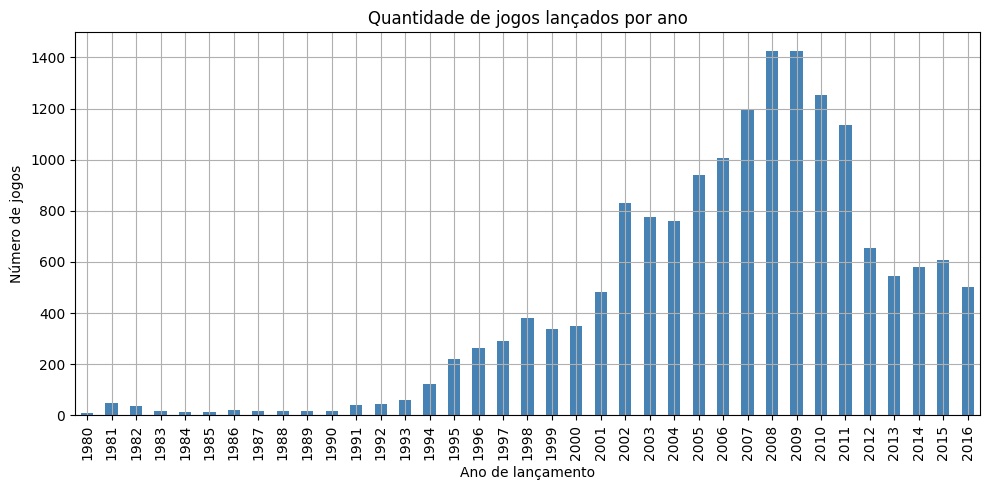

2002     829
2003     775
2004     762
2005     939
2006    1006
2007    1197
2008    1427
2009    1426
2010    1255
2011    1136
2012     653
2013     544
2014     581
2015     606
2016     502
Name: year_of_release, dtype: Int64

In [57]:
games_per_year = df['year_of_release'].value_counts().sort_index()

fig, ax = plt.subplots()
games_per_year.plot(kind='bar', ax=ax, color='steelblue')
ax.set_title('Quantidade de jogos lançados por ano')
ax.set_xlabel('Ano de lançamento')
ax.set_ylabel('Número de jogos')
plt.tight_layout()
plt.show()

games_per_year.tail(15)

**Observações:**

- **Os dados de cada período são significativos?**
    Não, uniformemente. De **1980 a 1993**, o número de lançamentos catalogados por ano é muito baixo (entre 9 e 60 jogos,
  ex.: 9 em 1980, 46 em 1981, 17 em 1983) — uma amostra pequena demais para que médias,
  medianas ou tendências calculadas ano a ano sejam confiáveis ou representativas do
  mercado da época. O volume só passa a ser estatisticamente robusto a partir de
  **meados dos anos 1990** (1994 já traz 121 lançamentos, e o crescimento continua até o
  pico em 2008-2009, com mais de 1.400 jogos/ano).
  Por isso, os anos anteriores a meados dos anos 1990 não devem ser usados para tirar conclusões quantitativas, e serão
  desconsiderados adiante, quando definirmos o período relevante para a modelagem.
- **A queda em 2016 é uma tendência real ou um artefato de coleta incompleta?**

  O gráfico mostra uma queda visível entre 2015 (606 lançamentos) e 2016 (502 lançamentos), uma
  redução de ~17%. Isso é coerente com a advertência do enunciado de que **os dados de
  2016 podem estar incompletos** (o dataset provavelmente não cobre o ano inteiro), ou
  seja, a queda observada **não deve ser lida como uma retração real do mercado**, e sim,
  ao menos em boa parte, como um efeito de a coleta ter sido interrompida antes do fim do
  ano. Esse ponto é importante porque **2016 será incluído na janela de dados usada para
  a modelagem de 2017** (Etapa 3.3): qualquer métrica de 2016 (contagem de lançamentos,
  vendas totais, etc.) deve ser interpretada como um **piso, não como o valor real do
  ano**, e comparações diretas entre 2016 e os anos anteriores completos (2013-2015)
  tendem a subestimar o desempenho de 2016.
  

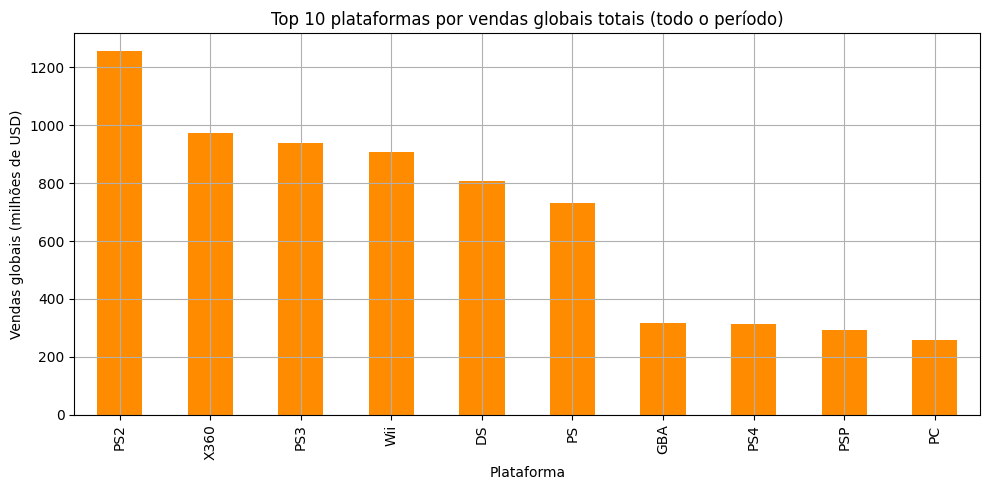

platform
PS2     1255.77
X360     971.42
PS3      939.65
Wii      907.51
DS       806.12
PS       730.86
GBA      317.85
PS4      314.14
PSP      294.05
PC       259.52
Name: total_sales, dtype: float64

In [58]:
# Total de vendas globais por plataforma, para identificar as plataformas historicamente
# mais relevantes em todo o período coberto.
sales_by_platform_total = (
    df.groupby('platform')['total_sales'].sum().sort_values(ascending=False)
)

fig, ax = plt.subplots()
sales_by_platform_total.head(10).plot(kind='bar', ax=ax, color='darkorange')
ax.set_title('Top 10 plataformas por vendas globais totais (todo o período)')
ax.set_xlabel('Plataforma')
ax.set_ylabel('Vendas globais (milhões de USD)')
plt.tight_layout()
plt.show()

sales_by_platform_total.head(10)

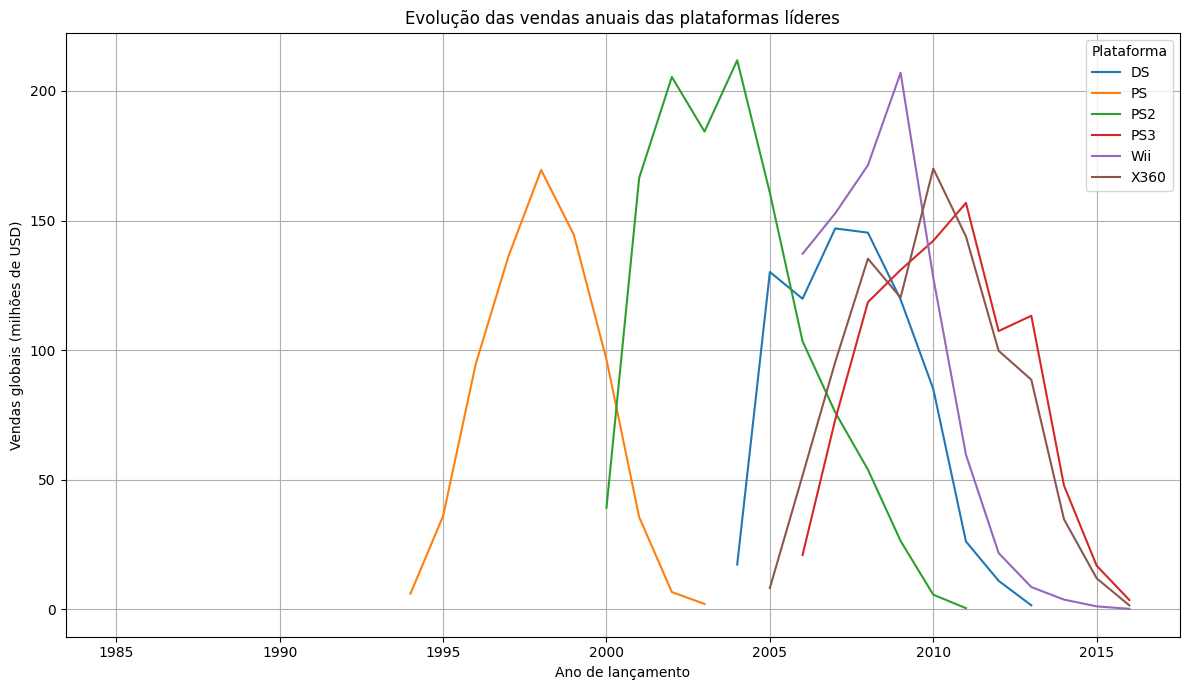

In [59]:
# Distribuição das vendas ao longo dos anos para plataformas líderes,
# para visualizar o ciclo de vida de cada uma

top_platforms = sales_by_platform_total.head(6).index.tolist()

pivot_platform_year = (
    df[df['platform'].isin(top_platforms)]
    .pivot_table(index='year_of_release', columns='platform', values='total_sales', aggfunc='sum')
)

fig, ax = plt.subplots(figsize=(12, 7))
pivot_platform_year.plot(ax=ax)
ax.set_title('Evolução das vendas anuais das plataformas líderes')
ax.set_xlabel('Ano de lançamento')
ax.set_ylabel('Vendas globais (milhões de USD)')
ax.legend(title='Plataforma')
plt.tight_layout()

plt.show()

In [60]:
# Para estimar o "tempo de vida" típico de uma plataforma, calculamos o primeiro
# e o último ano com vendas relevantes para cada plataforma/intervalo entre eles

platform_lifespan = (
    df.dropna(subset=['year_of_release'])
    .groupby('platform')['year_of_release']
    .agg(primeiro_ano='min', ultimo_ano='max')
)
platform_lifespan['duracao_anos'] = platform_lifespan['ultimo_ano'] - platform_lifespan['primeiro_ano']
platform_lifespan.sort_values('ultimo_ano', ascending=False).head(15)

,primeiro_ano,ultimo_ano,duracao_anos
platform,,,
XOne,2013,2016,3
3DS,2011,2016,5
X360,2005,2016,11
WiiU,2012,2016,4
Wii,2006,2016,10
PSV,2011,2016,5
PC,1985,2016,31
PS4,2013,2016,3
PS3,2006,2016,10


In [61]:
# Médias
print(f"Duração média de vida de uma plataforma: {platform_lifespan['duracao_anos'].mean():.1f} anos")
print(f"Duração mediana de vida de uma plataforma: {platform_lifespan['duracao_anos'].median():.1f} anos")

Duração média de vida de uma plataforma: 7.6 anos
Duração mediana de vida de uma plataforma: 6.0 anos


In [62]:
# Novos lançamentos de plataformas por ano, para identificar quando a geração
# atual (de 2017 PS4/XOne/3DS/PC, etc.) começou a ganhar espaço

new_platforms_per_year = (
    df.dropna(subset=['year_of_release'])
    .groupby('platform')['year_of_release'].min()
    .value_counts()
    .sort_index()
)
new_platforms_per_year.tail(15)

1992    1
1993    2
1994    3
1995    1
1996    2
1998    1
1999    1
2000    3
2001    1
2004    1
2005    1
2006    2
2011    2
2012    1
2013    2
Name: year_of_release, dtype: Int64

In [63]:
# Com base no ciclo médio de vida ajustaremos o período para 2013 a 2016
# consideraremos apenas df_recent a partir daqui

df_recent = df[(df['year_of_release'] >= 2013) & (df['year_of_release'] <= 2016)].copy()
print(f'Registros no período 2013-2016: {len(df_recent)} (de {len(df)} no total)')

Registros no período 2013-2016: 2233 (de 16713 no total)


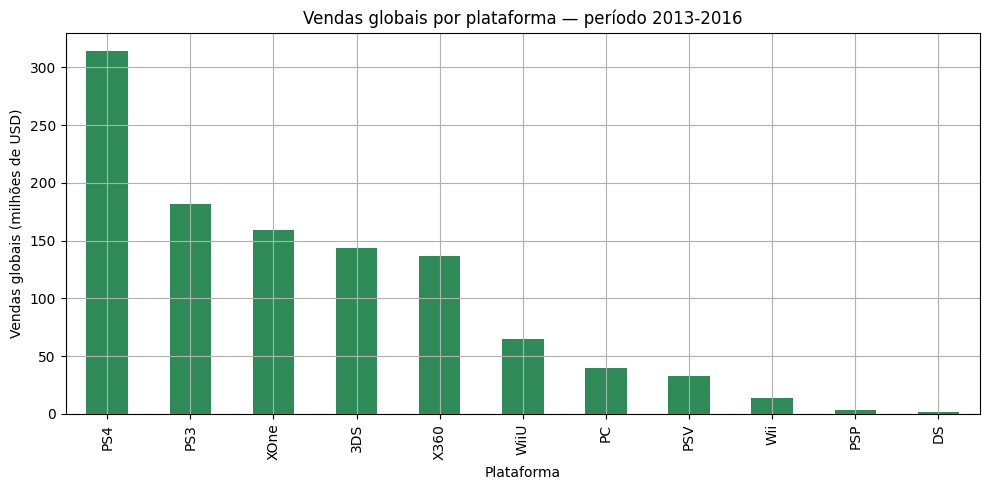

platform
PS4     314.14
PS3     181.43
XOne    159.32
3DS     143.25
X360    136.80
WiiU     64.63
PC       39.43
PSV      32.99
Wii      13.66
PSP       3.50
DS        1.54
Name: total_sales, dtype: float64

In [64]:
sales_by_platform_recent = (
    df_recent.groupby('platform')['total_sales'].sum().sort_values(ascending=False)
)

fig, ax = plt.subplots()
sales_by_platform_recent.plot(kind='bar', ax=ax, color='seagreen')
ax.set_title('Vendas globais por plataforma — período 2013-2016')
ax.set_xlabel('Plataforma')
ax.set_ylabel('Vendas globais (milhões de USD)')
plt.tight_layout()
plt.show()

sales_by_platform_recent

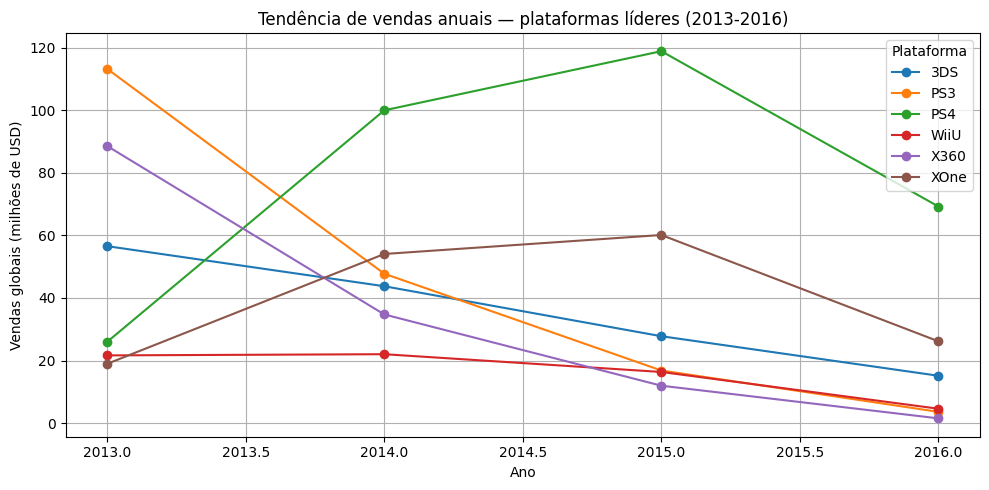

platform,3DS,PS3,PS4,WiiU,X360,XOne
year_of_release,,,,,,
2013,56.57,113.25,25.99,21.65,88.58,18.96
2014,43.76,47.76,100.00,22.03,34.74,54.07
2015,27.78,16.82,118.90,16.35,11.96,60.14
2016,15.14,3.60,69.25,4.60,1.52,26.15


In [65]:
# Tendência ano a ano das plataformas líderes no período recente,
# para identificar quais estão em ascensão e quais em queda às vésperas de 2017.

top_recent_platforms = sales_by_platform_recent.head(6).index.tolist()

pivot_recent = (
    df_recent[df_recent['platform'].isin(top_recent_platforms)]
    .pivot_table(index='year_of_release', columns='platform', values='total_sales', aggfunc='sum')
)

fig, ax = plt.subplots(figsize=(10, 5))
pivot_recent.plot(marker='o', ax=ax)
ax.set_title('Tendência de vendas anuais — plataformas líderes (2013-2016)')
ax.set_xlabel('Ano')
ax.set_ylabel('Vendas globais (milhões de USD)')
ax.legend(title='Plataforma')
plt.tight_layout()
plt.show()

pivot_recent

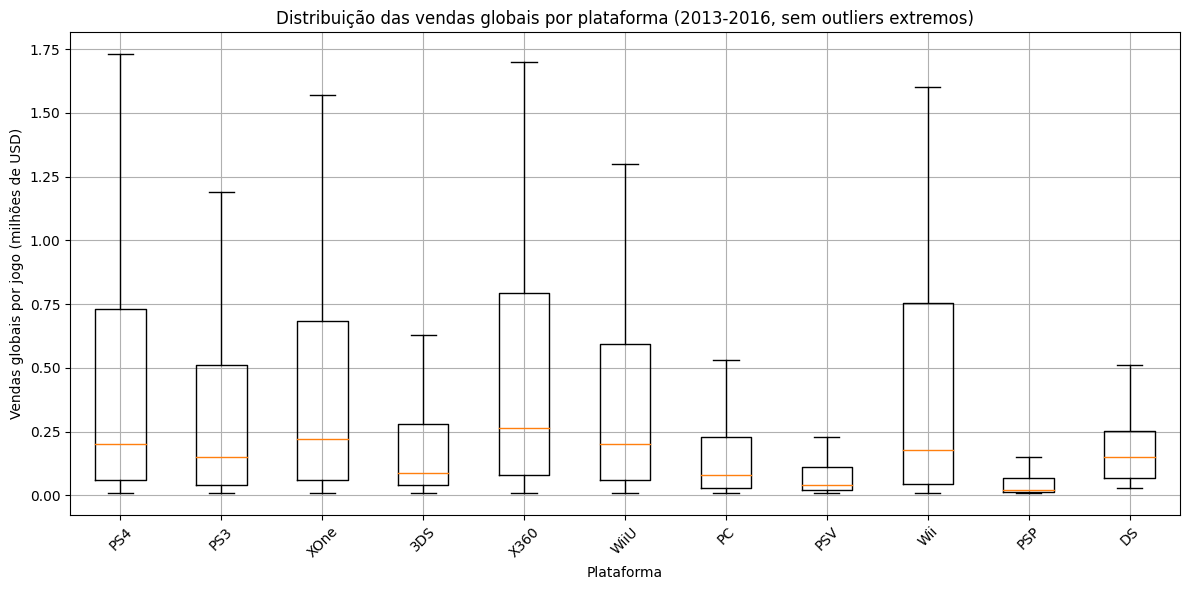

,media,mediana,desvio_padrao,variancia,qtd_jogos
platform,,,,,
PS4,0.801378,0.200,1.609456,2.590350,392
X360,0.735484,0.265,1.663275,2.766484,186
XOne,0.645020,0.220,1.036139,1.073584,247
Wii,0.593913,0.180,0.915432,0.838016,23
WiiU,0.562000,0.200,1.038778,1.079060,115
PS3,0.525884,0.150,1.451939,2.108128,345
3DS,0.472772,0.090,1.381347,1.908119,303
PC,0.208624,0.080,0.352304,0.124118,189
DS,0.192500,0.150,0.172026,0.029593,8


In [66]:
# Boxplot das vendas globais por plataforma (período mais relevante),
# para comparar a dispersão e os valores típicos de venda entre plataformas

platform_order = sales_by_platform_recent.index.tolist()

fig, ax = plt.subplots(figsize=(12, 6))
data_to_plot = [df_recent.loc[df_recent['platform'] == p, 'total_sales'] for p in platform_order]

ax.boxplot(data_to_plot, showfliers=False)

ax.set_xticks(range(1, len(platform_order) + 1))
ax.set_xticklabels(platform_order)
ax.set_title('Distribuição das vendas globais por plataforma (2013-2016, sem outliers extremos)')
ax.set_xlabel('Plataforma')
ax.set_ylabel('Vendas globais por jogo (milhões de USD)')
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

platform_stats = (
    df_recent.groupby('platform')['total_sales']
    .agg(media='mean', mediana='median', desvio_padrao='std', variancia='var', qtd_jogos='count')
    .sort_values('media', ascending=False))
platform_stats


**Observações:**

- **As diferenças entre plataformas são significativas.** A média de vendas por jogo
  varia quase **16 vezes** entre a líder (**PS4**, 0,80 milhão) e a última colocada
  (**PSP**, 0,05 milhão). Mesmo entre as plataformas do topo, PS4 (0,80) supera PSV
  (0,09) em quase 9 vezes, a posição da plataforma no ciclo de vida (Etapa 3.4) se
  reflete diretamente na vendagem típica de cada jogo lançado nela.
  
- **Média sempre bem acima da mediana, em todas as plataformas.** Por exemplo, no PS4 a
  média é 0,80 milhão, mas a mediana é apenas 0,20 milhão; no X360 a média é 0,74 contra
  mediana de 0,27. Essa distância grande e sistemática indica uma **distribuição
  assimétrica à direita**: a maioria dos jogos vende pouco (a mediana é a medida mais
  representativa do "jogo típico"), enquanto **poucos títulos "blockbuster"** têm vendas
  muito acima do normal e puxam a média para cima, são justamente esses outliers que o
  boxplot omite visualmente (`showfliers=False`), mas que aparecem no desvio padrão e na
  variância elevados de PS4, X360 e PS3.

  
- **PS4 e XOne** combinam a maior média de vendas com boa consistência (o XOne tem
  desvio padrão/variância bem menores que PS3, X360 ou 3DS para uma média parecida),
  reforçando por que são as apostas mais seguras para 2017: alto volume de vendas *e*
  menor risco de um lançamento performar muito abaixo do esperado.

  
- Plataformas em fim de ciclo (**PSP, PSV, DS**) têm médias e medianas baixas e desvios
  padrão pequenos, sinal de que não há mais "grandes sucessos" sendo lançados nelas,
  apenas vendas modestas e homogêneas.

  

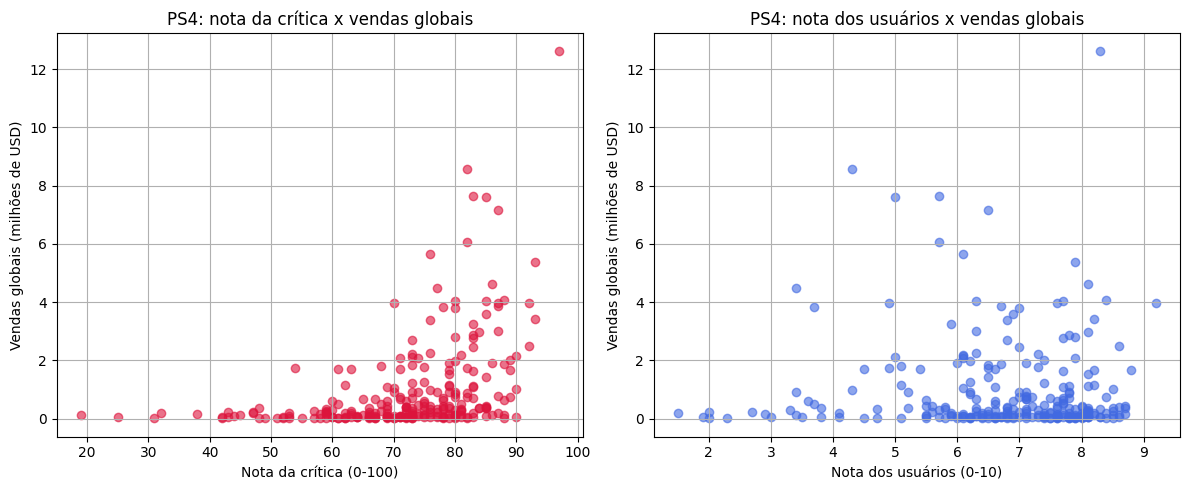

In [67]:
platform_choice = 'PS4'
df_platform = df_recent[df_recent['platform'] == platform_choice].dropna(
    subset=['critic_score', 'total_sales']
)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].scatter(df_platform['critic_score'], df_platform['total_sales'], alpha=0.6, color='crimson')
axes[0].set_title(f'{platform_choice}: nota da crítica x vendas globais')
axes[0].set_xlabel('Nota da crítica (0-100)')
axes[0].set_ylabel('Vendas globais (milhões de USD)')

df_platform_user = df_recent[df_recent['platform'] == platform_choice].dropna(
    subset=['user_score', 'total_sales']
)
axes[1].scatter(df_platform_user['user_score'], df_platform_user['total_sales'], alpha=0.6, color='royalblue')
axes[1].set_title(f'{platform_choice}: nota dos usuários x vendas globais')
axes[1].set_xlabel('Nota dos usuários (0-10)')
axes[1].set_ylabel('Vendas globais (milhões de USD)')

plt.tight_layout()
plt.show()

In [68]:
corr_critic = df_platform['critic_score'].corr(df_platform['total_sales'])
corr_user = df_platform_user['user_score'].corr(df_platform_user['total_sales'])
print(f'Correlação (nota da crítica x vendas) em {platform_choice}: {corr_critic:.3f}')
print(f'Correlação (nota dos usuários x vendas) em {platform_choice}: {corr_user:.3f}')

Correlação (nota da crítica x vendas) em PS4: 0.407
Correlação (nota dos usuários x vendas) em PS4: -0.032


In [69]:
# Seleciona jogos presentes em mais de uma plataforma no período relevante,
# para verificar se o padrão nota-venda observado em PS4 se repete em outras plataformas

multi_platform_games = (df_recent.groupby('name')['platform'].nunique())

multi_platform_titles = multi_platform_games[multi_platform_games > 1].index

comparison = (df_recent[df_recent['name'].isin(multi_platform_titles)]
    .pivot_table(index='name', columns='platform', values='total_sales', aggfunc='sum'))

print(f'Jogos lançados em mais de uma plataforma no período: {len(multi_platform_titles)}')

# A pivot completa tem uma coluna por plataforma, então a maioria das linhas fica cheia
# de NaN (cada jogo só sai em algumas plataformas). Para exibir uma amostra legível,
# usamos thresh=3: mantém só os títulos presentes em pelo menos 3 plataformas
# simultaneamente, priorizando os exemplos mais completos e informativos para a
# comparação visual (o cálculo de participação percentual abaixo, porém, usa a base
# completa de 473 títulos, sem esse filtro).

comparison.dropna(thresh=3).head(10)

Jogos lançados em mais de uma plataforma no período: 473


platform,3DS,DS,PC,PS3,PS4,PSP,PSV,Wii,WiiU,X360,XOne
name,,,,,,,,,,,
Adventure Time: Explore the Dungeon Because I Don't Know!,0.14,NaN,NaN,0.04,NaN,NaN,NaN,NaN,0.03,0.08,NaN
Adventure Time: Finn & Jake Investigations,0.09,NaN,NaN,0.08,0.10,NaN,NaN,NaN,0.05,0.09,0.05
Aegis of Earth: Protonovus Assault,NaN,NaN,NaN,0.02,0.02,NaN,0.03,NaN,NaN,NaN,NaN
Akiba's Trip: Undead & Undressed,NaN,NaN,NaN,0.11,0.11,NaN,0.15,NaN,NaN,NaN,NaN
Alien: Isolation,NaN,NaN,0.15,0.33,1.12,NaN,NaN,NaN,NaN,0.27,0.50
Aliens: Colonial Marines,NaN,NaN,0.18,0.60,NaN,NaN,NaN,NaN,NaN,0.77,NaN
Angry Birds Star Wars,0.33,NaN,NaN,0.29,0.22,NaN,0.08,0.26,0.10,0.28,0.17
Arslan: The Warriors of Legend,NaN,NaN,NaN,0.05,0.09,NaN,NaN,NaN,NaN,NaN,0.01
Assassin's Creed Chronicles,NaN,NaN,NaN,NaN,0.08,NaN,0.07,NaN,NaN,NaN,0.01


In [70]:
# A tabela bruta acima mostra as vendas lado a lado, mas não diz, de forma resumida,
# QUAL plataforma costuma "levar a maior fatia" quando um jogo sai em várias ao mesmo
# tempo. Para responder isso, calculamos, para cada título compartilhado, a participação
# percentual de cada plataforma nas vendas totais daquele título.

shared_games = df_recent[df_recent['name'].isin(multi_platform_titles)].copy()
totais_por_titulo = shared_games.groupby('name')['total_sales'].transform('sum')
shared_games['participacao_pct'] = shared_games['total_sales'] / totais_por_titulo * 100

# Participação média de cada plataforma nas vendas dos títulos que ela compartilha
# com outras plataformas, e em quantos desses títulos ela está presente
platform_share_summary = (
    shared_games.groupby('platform')['participacao_pct']
    .agg(participacao_media_pct='mean', qtd_titulos_compartilhados='count')
    .sort_values('participacao_media_pct', ascending=False))

platform_share_summary

,participacao_media_pct,qtd_titulos_compartilhados
platform,,
PS4,50.569926,316
PS3,35.456130,277
PSV,34.954190,140
3DS,34.697411,62
PSP,32.539266,14
DS,32.468647,8
X360,26.893663,180
Wii,25.241400,22
XOne,24.823796,224


In [71]:
# Complementarmente: em quantos títulos compartilhados cada plataforma foi a
# "vencedora" (maior venda entre as plataformas em que o jogo saiu)?

titulo_lider = shared_games.loc[shared_games.groupby('name')['total_sales'].idxmax()]
leader_counts = titulo_lider['platform'].value_counts()

leader_counts

PS4     238
PS3      87
PSV      46
X360     33
3DS      29
XOne     10
WiiU     10
Wii       7
PC        6
DS        5
PSP       2
Name: platform, dtype: int64

**Observações:** entre os **473 jogos** lançados em mais de uma plataforma no período
2013-2016, o **PS4 captura, em média, aprox. 51% das vendas** de cada título compartilhado, e é
a plataforma "vencedora" (maior venda) em **238 dos 473 títulos (aprox. 50%)**, uma dominância
bem maior do que sua participação geral em vendas (Etapa 3.4) já sugeria. É notável que o
**Xbox One**, apesar de ser a **3ª maior plataforma em vendas totais no período** (atrás
de PS4 e PS3, conforme a Etapa 3.4), tem participação média baixa nos títulos
compartilhados (aprox. 25%) e lidera em apenas **10** deles, ou seja, o volume de vendas do
XOne vem mais de sua base instalada geral do que de "vencer" a concorrência direta
título a título. Plataformas legadas como **PS3** e **PSV** ainda aparecem com
participação média relevante (aprox. 35%) nesses títulos compartilhados, reforçando a leitura
da Etapa 3.4 de que a base de usuários dessas plataformas ainda consumia lançamentos
multiplataforma no período, mesmo em declínio. Esse padrão confirma o **PS4 como a
plataforma mais segura para uma campanha em 2017**: além de vender mais no total, ela
tende a concentrar a maior fatia das vendas mesmo quando o jogo está disponível em
outras plataformas.

In [72]:
for plat in top_recent_platforms:
    sub = df_recent[df_recent['platform'] == plat].dropna(subset=['critic_score', 'total_sales'])
    if len(sub) > 5:
        print(f'{plat}: correlação nota da crítica x vendas = {sub["critic_score"].corr(sub["total_sales"]):.3f} (n={len(sub)})')

PS4: correlação nota da crítica x vendas = 0.407 (n=252)
PS3: correlação nota da crítica x vendas = 0.334 (n=121)
XOne: correlação nota da crítica x vendas = 0.417 (n=169)
3DS: correlação nota da crítica x vendas = 0.357 (n=71)
X360: correlação nota da crítica x vendas = 0.350 (n=81)
WiiU: correlação nota da crítica x vendas = 0.376 (n=70)


Distribuição de jogos por gênero

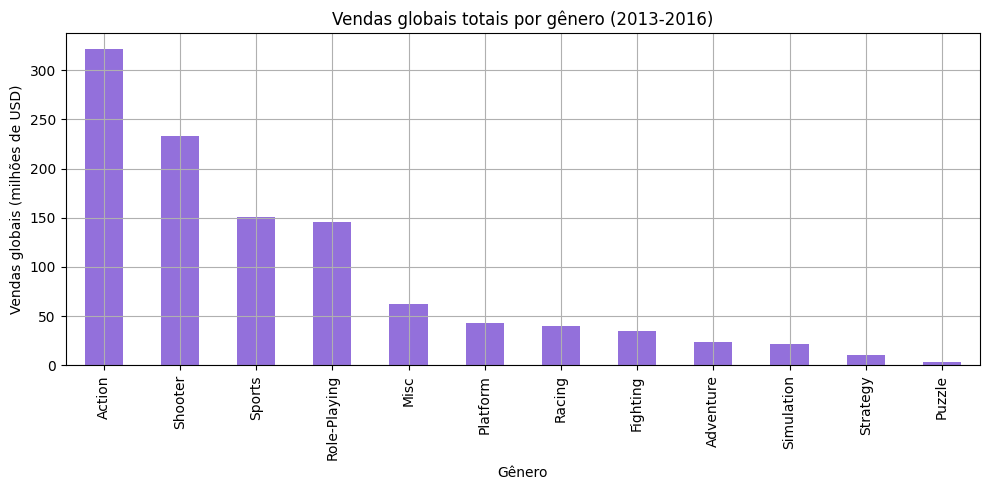

,vendas_totais,vendas_medias,qtd_jogos
genre,,,
Action,321.87,0.420196,766
Shooter,232.98,1.245882,187
Sports,150.65,0.703972,214
Role-Playing,145.89,0.499623,292
Misc,62.82,0.405290,155
Platform,42.63,0.576081,74
Racing,39.89,0.469294,85
Fighting,35.31,0.441375,80
Adventure,23.64,0.096490,245


In [73]:
genre_stats = (
    df_recent.groupby('genre')['total_sales']
    .agg(vendas_totais='sum', vendas_medias='mean', qtd_jogos='count')
    .sort_values('vendas_totais', ascending=False))

fig, ax = plt.subplots()
genre_stats['vendas_totais'].plot(kind='bar', ax=ax, color='mediumpurple')
ax.set_title('Vendas globais totais por gênero (2013-2016)')
ax.set_xlabel('Gênero')
ax.set_ylabel('Vendas globais (milhões de USD)')

plt.tight_layout()
plt.show()

genre_stats

Etapa 4. Perfil de usuário por região (AN, UE, JP)

--- AN (América do Norte) ---
platform
PS4     108.74
XOne     93.12
X360     81.66
PS3      63.50
3DS      38.20
Name: na_sales, dtype: float64 

--- UE (Europa) ---
platform
PS4     141.09
PS3      67.81
XOne     51.59
X360     42.52
3DS      30.96
Name: eu_sales, dtype: float64 

--- JP (Japão) ---
platform
3DS     67.81
PS3     23.35
PSV     18.59
PS4     15.96
WiiU    10.88
Name: jp_sales, dtype: float64 



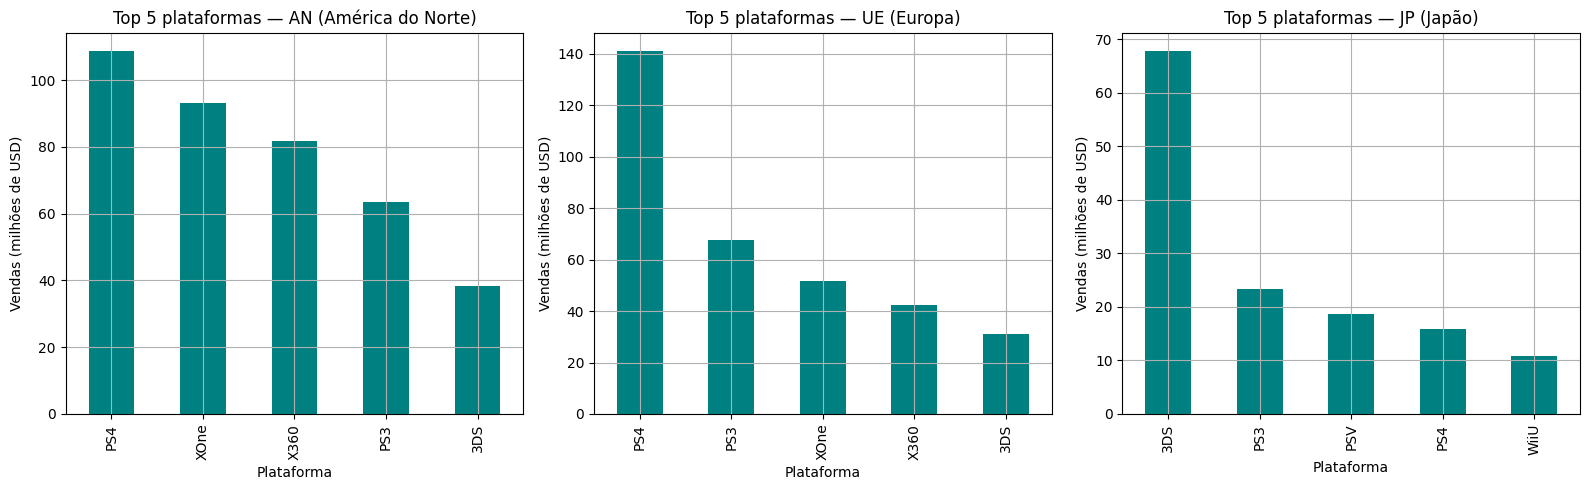

In [74]:
regions = {
    'AN (América do Norte)': 'na_sales',
    'UE (Europa)': 'eu_sales',
    'JP (Japão)': 'jp_sales',}

top_platforms_by_region = {}
for region_name, col in regions.items():
    top5 = df_recent.groupby('platform')[col].sum().sort_values(ascending=False).head(5)
    top_platforms_by_region[region_name] = top5
    print(f'--- {region_name} ---')
    print(top5, '\n')

fig, axes = plt.subplots(1, 3, figsize=(16, 5), sharey=False)

for ax, (region_name, top5) in zip(axes, top_platforms_by_region.items()):
    top5.plot(kind='bar', ax=ax, color='teal')
    ax.set_title(f'Top 5 plataformas — {region_name}')
    ax.set_xlabel('Plataforma')
    ax.set_ylabel('Vendas (milhões de USD)')

plt.tight_layout()
plt.show()

**Observações:** em **AN** (Action 126 mi, Shooter 110 mi) e **UE** (Action 118 mi,
Shooter 88 mi), **Action** e **Shooter** lideram claramente as preferências de gênero, e
o restante do Top 5 é quase idêntico entre as duas regiões (Sports, Role-Playing, e
Misc/Racing como quinto colocado), reforçando o perfil de consumo muito parecido entre
os dois mercados ocidentais já observado na Etapa 4.1.

No **Japão**, o padrão se inverte: **Role-Playing (RPG)** lidera com folga (51,04 mi),
à frente até de **Action** (40,49 mi), enquanto **Shooter** cai para a última posição do
Top 5 (6,61 mi), uma posição irrelevante perto do 2º lugar que ocupa em AN/UE. Essa
diferença tem raízes históricas e culturais da indústria: o mercado japonês foi formado
em torno de franquias de RPG domésticas de décadas (como *Dragon Quest* e *Final
Fantasy*), com um público fiel a esse estilo de narrativa e progressão de personagem; já
o gênero Shooter, historicamente dominado por franquias ocidentais de temática militar
(como *Call of Duty*), nunca teve a mesma penetração cultural no Japão. Já **Action** e
**Shooter** no Ocidente se beneficiam de franquias anuais consolidadas e de um público
grande e recorrente, o que explica sua liderança folgada em AN/UE.

**Implicação para a campanha:** a segmentação por gênero precisa ser regional, Action/
Shooter/Sports para AN e UE, RPG para o Japão, e não um único mix de gêneros aplicado
globalmente.

--- AN (América do Norte) ---
genre
Action          126.05
Shooter         109.74
Sports           65.27
Role-Playing     46.40
Misc             27.49
Name: na_sales, dtype: float64 

--- UE (Europa) ---
genre
Action          118.13
Shooter          87.86
Sports           60.52
Role-Playing     36.97
Racing           20.19
Name: eu_sales, dtype: float64 

--- JP (Japão) ---
genre
Role-Playing    51.04
Action          40.49
Misc             9.20
Fighting         7.65
Shooter          6.61
Name: jp_sales, dtype: float64 



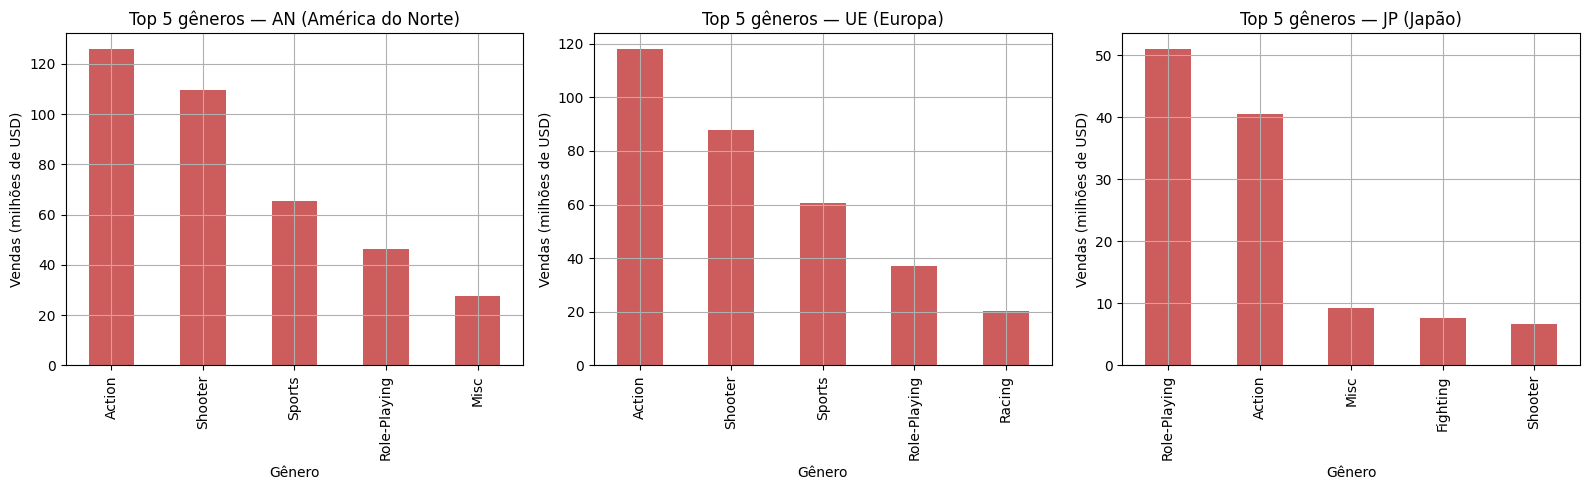

In [75]:
top_genres_by_region = {}

for region_name, col in regions.items():
    top5 = df_recent.groupby('genre')[col].sum().sort_values(ascending=False).head(5)
    top_genres_by_region[region_name] = top5
    print(f'--- {region_name} ---')
    print(top5, '\n')

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, (region_name, top5) in zip(axes, top_genres_by_region.items()):
    
    top5.plot(kind='bar', ax=ax, color='indianred')
    ax.set_title(f'Top 5 gêneros — {region_name}')
    ax.set_xlabel('Gênero')
    ax.set_ylabel('Vendas (milhões de USD)')
    
plt.tight_layout()
plt.show()

**Observações:** em **AN** (Action 126 mi, Shooter 110 mi) e **UE** (Action 118 mi,
Shooter 88 mi), **Action** e **Shooter** lideram claramente as preferências de gênero, e
o restante do Top 5 é quase idêntico entre as duas regiões (Sports, Role-Playing, e
Misc/Racing como quinto colocado), reforçando o perfil de consumo muito parecido entre
os dois mercados ocidentais já observado na Etapa 4.1.

No **Japão**, o padrão se inverte: **Role-Playing (RPG)** lidera com folga (51,04 mi),
à frente até de **Action** (40,49 mi), enquanto **Shooter** cai para a última posição do
Top 5 (6,61 mi), uma posição irrelevante perto do 2º lugar que ocupa em AN/UE. Essa
diferença tem raízes históricas e culturais da indústria: o mercado japonês foi formado
em torno de franquias de RPG domésticas de décadas (como *Dragon Quest* e *Final
Fantasy*), com um público fiel a esse estilo de narrativa e progressão de personagem; já
o gênero Shooter, historicamente dominado por franquias ocidentais de temática militar
(como *Call of Duty*), nunca teve a mesma penetração cultural no Japão. Já **Action** e
**Shooter** no Ocidente se beneficiam de franquias anuais consolidadas e de um público
grande e recorrente, o que explica sua liderança folgada em AN/UE.

**Implicação para a campanha:** a segmentação por gênero precisa ser regional, Action/
Shooter/Sports para AN e UE, RPG para o Japão — e não um único mix de gêneros aplicado
globalmente.

--- AN (América do Norte) ---
rating
M       165.21
E        79.05
E10+     54.24
T        49.79
Name: na_sales, dtype: float64 

--- UE (Europa) ---
rating
M       145.32
E        83.36
E10+     42.69
T        41.95
Name: eu_sales, dtype: float64 

--- JP (Japão) ---
rating
T       20.59
E       15.14
M       14.11
E10+     5.89
Name: jp_sales, dtype: float64 



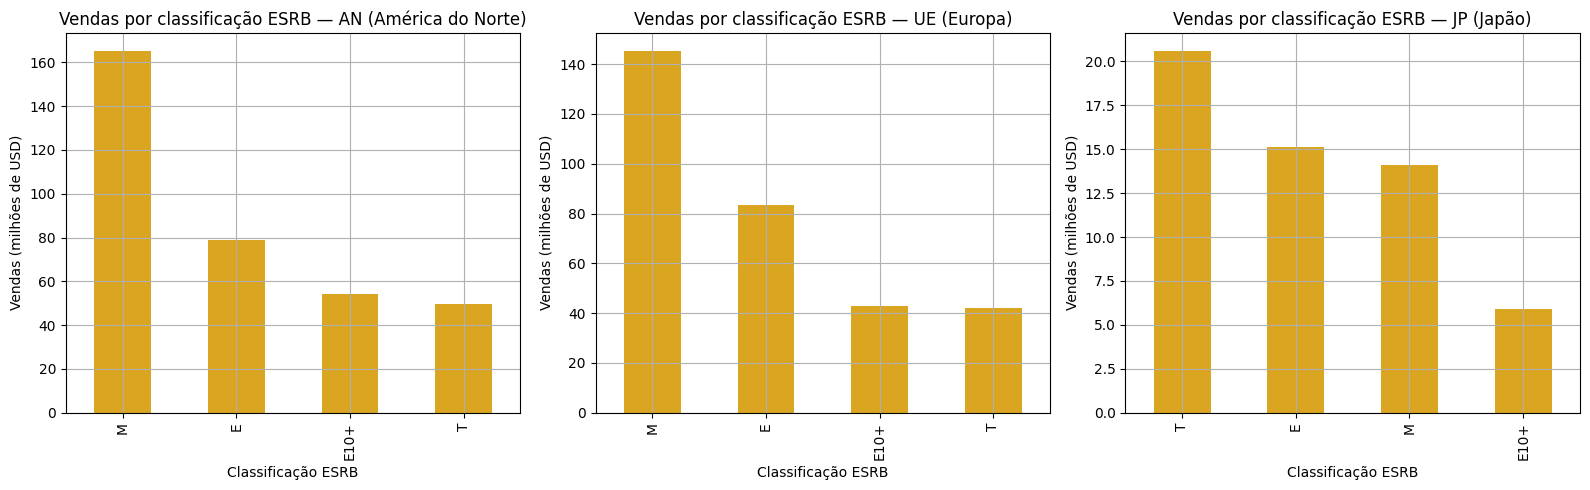

In [76]:
rating_by_region = {}
for region_name, col in regions.items():
    tab = (
        df_recent.dropna(subset=['rating'])
        .groupby('rating', observed=True)[col].sum()
        .sort_values(ascending=False))
    
    rating_by_region[region_name] = tab
    print(f'--- {region_name} ---')
    print(tab, '\n')

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, (region_name, tab) in zip(axes, rating_by_region.items()):
    tab.plot(kind='bar', ax=ax, color='goldenrod')
    ax.set_title(f'Vendas por classificação ESRB — {region_name}')
    ax.set_xlabel('Classificação ESRB')
    ax.set_ylabel('Vendas (milhões de USD)')
    
plt.tight_layout()
plt.show()

**Sim, a classificação ESRB afeta as vendas — mas de forma diferente em cada região.**

1>Em **AN** (165,21 mi) e **UE** (145,32 mi), a classificação **M (Mature)** é
  disparadamente a que mais vende, seguida por **E (Everyone)** (79,05 mi em AN e 83,36
  mi em UE) — reflexo das franquias de ação/tiro muito populares entre o público adulto
  nesses dois mercados ocidentais, que têm perfil de gênero muito parecido entre si
  (Etapa 4.2).
  
2>No **Japão**, o padrão se **inverte**: **T (Teen)** lidera as vendas (20,59 mi),
  **superando tanto E (15,14 mi) quanto M (14,11 mi)** — ou seja, ao contrário de AN/UE,
  o público japonês não concentra suas compras em jogos para adultos, e sim em títulos
  de classificação intermediária, consistente com a preferência por RPGs (muitos deles
  classificados como T) já identificada na Etapa 4.2.
  
3>Em volume absoluto, o efeito da ESRB é **muito mais forte em AN e UE** (dezenas de
  milhões de USD de diferença entre classificações) do que no Japão (diferenças de
  poucos milhões) — em parte porque boa parte dos jogos vendidos no Japão não possui
  classificação ESRB atribuída (o mercado japonês usa seu próprio sistema, o CERO), o
  que reduz a base de dados classificada e a representatividade da análise para essa
  região.

**Implicação prática:** para a campanha de 2017, a classificação ESRB é um critério de
segmentação útil e forte em **AN/UE** (priorizar títulos **M** e **E**), mas **pouco
confiável como critério isolado no Japão**, onde o gênero (RPG) é um sinal mais forte do
que a faixa etária ESRB.

Etapa 5. Teste de hipóteses estatísticas

Hip. 01 - XOne vs PC

H0 (hipótese nula): as notas médias de usuários das plataformas Xbox One e PC são iguais (não há diferença estatisticamente significativa entre as médias).

H1 (hipótese alternativa): as notas médias de usuários das plataformas Xbox One e PC são diferentes.

**Nível de significância escolhido e por quê:** `alpha = 0.05` (5%).

O valor de alfa define o **risco de falso positivo** que estamos dispostos a aceitar, 
ou seja, a chance de concluirmos que existe diferença entre as médias quando, na
verdade, não existe (rejeitar H0 sendo ela verdadeira). 

Quanto **menor** o alfa, mais
"exigente" fica o teste e menor o risco de falso positivo, mas maior o risco do erro
oposto: deixar de detectar uma diferença real que existe (falso negativo). 
A escolha de alfa é, portanto, um trade-off entre esses dois riscos, e o valor apropriado depende de
**quão caro é errar em cada direção** e de **quão confiantes precisamos estar antes de
agir** sobre o resultado.

Neste caso, o resultado do teste alimenta uma decisão de **marketing** (por exemplo,
decidir se vale segmentar campanhas de forma diferente para Xbox One e PC, ou tratar
Action e Sports como públicos com preferências de avaliação distintas), não uma decisão
crítica de segurança, saúde ou finanças, onde um falso positivo teria consequência grave
e justificaria um alfa bem mais conservador (0,01 ou menor). Aqui, o custo de um falso
positivo é moderado (na pior hipótese, uma campanha um pouco mal segmentada) e o custo de
um falso negativo (não perceber uma diferença real entre os públicos) também não é
crítico, apenas uma oportunidade de refinamento perdida. 

Por isso, **5% é um limiar equilibrado**: exige uma evidência razoavelmente forte nos dados antes de afirmarmos que
existe diferença entre os grupos, mas sem ser tão rígido a ponto de mascarar diferenças
reais e moderadas, que é exatamente o tipo de sinal útil para uma decisão de negócio
como esta. Esse mesmo raciocínio vale igualmente para os dois testes desta seção por isso usamos o mesmo `alpha = 0.05` em ambos.


In [77]:
scores_xone = df_recent.loc[df_recent['platform'] == 'XOne', 'user_score'].dropna()
scores_pc = df_recent.loc[df_recent['platform'] == 'PC', 'user_score'].dropna()

print(f'Xbox One: n={len(scores_xone)}, média={scores_xone.mean():.3f}, desvio_padrao={scores_xone.std():.3f}, variancia={scores_xone.var():.3f}')
print(f'PC:       n={len(scores_pc)}, média={scores_pc.mean():.3f}, desvio_padrao={scores_pc.std():.3f}, variancia={scores_pc.var():.3f}')

alpha = 0.05

t_stat, p_value = stats.ttest_ind(scores_xone, scores_pc, equal_var=False)

print(f'Estatística t: {t_stat:.4f}')
print(f'p-valor: {p_value:.4f}')

if p_value < alpha:
    print('Rejeitamos H0: há evidência estatística de diferença entre as médias.')
else:
    print('Não rejeitamos H0: não há evidência estatística suficiente de diferença entre as médias.')
    

Xbox One: n=182, média=6.521, desvio_padrao=1.381, variancia=1.907
PC:       n=155, média=6.270, desvio_padrao=1.742, variancia=3.036
Estatística t: 1.4519
p-valor: 0.1476
Não rejeitamos H0: não há evidência estatística suficiente de diferença entre as médias.


Hip. 02 - Action vs Sports

H0 (hipótese nula): as notas médias de usuários para os gêneros Action e Sports são iguais.

H1 (hipótese alternativa): as notas médias de usuários para os gêneros Action e Sports são diferentes.

In [78]:
scores_action = df_recent.loc[df_recent['genre'] == 'Action', 'user_score'].dropna()

scores_sports = df_recent.loc[df_recent['genre'] == 'Sports', 'user_score'].dropna()

print(f'Action: n={len(scores_action)}, média={scores_action.mean():.3f}, desvio_padrao={scores_action.std():.3f}, variancia={scores_action.var():.3f}')
print(f'Sports: n={len(scores_sports)}, média={scores_sports.mean():.3f}, desvio_padrao={scores_sports.std():.3f}, variancia={scores_sports.var():.3f}')

t_stat2, p_value2 = stats.ttest_ind(scores_action, scores_sports, equal_var=False)

print(f'Estatística t: {t_stat2:.4f}')
print(f'p-valor: {p_value2:.4f}')

if p_value2 < alpha:
    print('Rejeitamos H0: há evidência estatística de diferença entre as médias.')
else:
    print('Não rejeitamos H0: não há evidência estatística suficiente de diferença entre as médias.')
    

Action: n=389, média=6.838, desvio_padrao=1.330, variancia=1.769
Sports: n=160, média=5.238, desvio_padrao=1.783, variancia=3.181
Estatística t: 10.2334
p-valor: 0.0000
Rejeitamos H0: há evidência estatística de diferença entre as médias.


Etapa 6. Conclusão geral

Tratamento e Período de Análise

1>Tratamento dos Dados: Padronização das variáveis, conversão de pontuações e inclusão da métrica de vendas globais. As ausências em notas e datas foram mantidas para evitar distorções estatísticas.

2>Janela Estudo (2013-2016): O mercado atingiu seu topo em 2008-2009. Como cada console mantém relevância por 4 a 6 anos (dentro de um ciclo de vida de 10 anos), os dados a partir de 2013 foram definidos como a base ideal para modelar 2017.

**Observações:**

- **PS4** e **Xbox One (XOne)** são as plataformas com maior volume de vendas do
  período, mas **não estão em crescimento constante**: ambas sobem de 2013 a 2015 (PS4:
  26,0 para 100,0 para 118,9 mi; XOne: 19,0 para 54,1 para 60,1 mi) e **caem em 2016** (PS4: 69,3 mi;
  XOne: 26,2 mi), um declínio claro no último ano de dados, não uma continuação da
  trajetória de alta.
  
- Como já observado na Etapa 1, **os dados de 2016 são reconhecidamente incompletos**
  (o dataset cobre apenas parte do ano), o que explica ao menos parte dessa queda, 
  mas não a explica por completo: mesmo pró-rateando, o formato da curva sugere que o
  pico de ambas já havia ficado para trás em 2015. Por isso, tratamos a queda de 2016
  como **parcialmente um artefato de coleta**, sem assumir que ela representa um
  esgotamento total das duas plataformas.

  
- **PS3**, **X360**, **3DS** e **WiiU** mostram **queda consistente** ano a ano, inclusive
  antes de 2016 — são plataformas da geração anterior (ou de nicho, no caso do WiiU),
  perdendo espaço para os sucessores de forma mais estrutural do que sazonal.

  
- **Plataformas potencialmente lucrativas para 2017:** mesmo com a queda de 2016, **PS4**
  e **XOne** seguem sendo as apostas mais seguras para uma campanha em 2017, elas
  lideram em vendas absolutas em todo o período e sua queda no último ano é atribuível,
  ao menos em parte, aos dados incompletos, enquanto o declínio das plataformas da
  geração anterior é consistente desde 2013 e não tem essa mesma ressalva.

Diferenças Regionais

- Ocidente (América do Norte e Europa): Padrão de consumo muito semelhante, focado em
  consoles modernos (PS4/Xbox One), gêneros de ação/tiro e títulos com classificação
  ESRB alta (M e E).
- Japão: Mercado com comportamento isolado, onde o portátil 3DS lidera, os jogos de RPG
  dominam e a marca Xbox tem presença irrelevante.

Esse padrão regional é coerente com o restante da análise: os gêneros mais lucrativos em
volume global, **Action**, **Shooter** e **Sports**, são justamente os que dominam o
consumo ocidental, enquanto o Japão foge dessa regra ao priorizar RPG. 
E, dentro desses gêneros líderes, a **nota da crítica especializada** segue sendo o sinal mais confiável
de sucesso comercial (correlação positiva moderada, ~0,41 no PS4), muito mais do que a
nota de usuários (~-0,03) — um critério que vale para orientar quais títulos priorizar
dentro de cada região, não só qual plataforma ou gênero escolher.

Estratégia Recomendada para 2017

-América do Norte e Europa: Concentrar esforços de marketing nos consoles PS4 e Xbox
   One, focando nos gêneros Ação, Tiro e Esportes com boa recepção da crítica e
   classificação M/E.
   
-Japão: Redirecionar a verba para RPGs focados nas plataformas Nintendo e PlayStation.

-Segmentação por gênero, não por plataforma: os testes de hipótese (Etapa 5) mostraram
   que a nota de usuários **não difere significativamente entre Xbox One e PC**
   (p = 0,1476), logo, a mesma mensagem de "aprovação dos jogadores" pode ser usada em
   campanhas para as duas plataformas, sem necessidade de discurso separado por
   console. Já a nota de usuários **difere significativamente entre os gêneros Action e
   Sports** (p < 0,0001), ou seja, a campanha deve tratar esses dois públicos de forma
   distinta, sem assumir que uma mesma peça publicitária ou expectativa de recepção
   funciona igualmente bem para os dois gêneros.